## Case study 1: E-commerce conversion
Question: which sessions are associated with purchase completion, and where does the funnel drop?
- Data: session_id, channel, device, pages_viewed, cart_value, time_on_site,
purchased.
- EDA: conversion by channel/device, missingness, cart-value distribution,
funnel stage counts.
- Features: pages_per_minute, cart_value_bucket, session_hour;
ensure features exist before prediction time.
- Deliverable: evidence-backed recommendations, limitations and a proposed
offline evaluation plan.

In [1]:
import pandas as pd
import numpy as np

# Generate sample dataset
np.random.seed(42)

n = 500

df = pd.DataFrame({
    "session_id": range(1, n + 1),

    "channel": np.random.choice(
        ["Organic", "Social Media", "Email", "Paid Ads"],
        n
    ),

    "device": np.random.choice(
        ["Mobile", "Desktop", "Tablet"],
        n
    ),

    "pages_viewed": np.random.randint(1, 20, n),

    "cart_value": np.random.choice(
        [0, 200, 500, 800, 1200, 2000, 3000],
        n
    ),

    "time_on_site": np.random.randint(30, 1200, n),

    "session_start": pd.date_range(
        start="2026-01-01",
        periods=n,
        freq="h"
    )
})

# Generate purchase status
score = (
    df["pages_viewed"] * 0.08 +
    df["cart_value"] * 0.0005 +
    df["time_on_site"] * 0.001
)

probability = 1 / (1 + np.exp(-(score - 2.5)))

df["purchased"] = np.where(
    np.random.random(n) < probability,
    1,
    0
)

# Add some missing values for EDA
df.loc[np.random.choice(n, 10, replace=False), "cart_value"] = np.nan

# Save CSV file
df.to_csv("ecommerce.csv", index=False)

print("E-commerce dataset created successfully!")
print("Dataset Shape:", df.shape)

df.head()

E-commerce dataset created successfully!
Dataset Shape: (500, 8)


,session_id,channel,device,pages_viewed,cart_value,time_on_site,session_start,purchased
0,1,Email,Tablet,10,800.0,965,2026-01-01 00:00:00,1
1,2,Paid Ads,Mobile,17,500.0,271,2026-01-01 01:00:00,1
2,3,Organic,Mobile,5,500.0,31,2026-01-01 02:00:00,1
3,4,Email,Tablet,2,0.0,254,2026-01-01 03:00:00,0
4,5,Email,Mobile,6,1200.0,830,2026-01-01 04:00:00,1


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    classification_report, confusion_matrix, average_precision_score
)

In [3]:
# 1. Load Dataset
df = pd.read_csv("ecommerce.csv")

print("First Five Records:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

First Five Records:
   session_id   channel  device  pages_viewed  cart_value  time_on_site  \
0           1     Email  Tablet            10       800.0           965   
1           2  Paid Ads  Mobile            17       500.0           271   
2           3   Organic  Mobile             5       500.0            31   
3           4     Email  Tablet             2         0.0           254   
4           5     Email  Mobile             6      1200.0           830   

         session_start  purchased  
0  2026-01-01 00:00:00          1  
1  2026-01-01 01:00:00          1  
2  2026-01-01 02:00:00          1  
3  2026-01-01 03:00:00          0  
4  2026-01-01 04:00:00          1  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   session_id     500 non-null    int64  
 1   channel        500 non-null    object 
 2   device

In [4]:
# 2. Data Cleaning
df = df.drop_duplicates(subset="session_id")

df["purchased"] = (
    df["purchased"].astype(str).str.lower()
    .map({"yes": 1, "true": 1, "1": 1,
          "no": 0, "false": 0, "0": 0})
)

df["session_start"] = pd.to_datetime(
    df["session_start"], errors="coerce"
)

In [5]:
# 3. EDA

print("\nPurchase Distribution:")
print(df["purchased"].value_counts())

print("\nConversion by Channel:")
print(df.groupby("channel")["purchased"].mean())

print("\nConversion by Device:")
print(df.groupby("device")["purchased"].mean())




Purchase Distribution:
purchased
0    308
1    192
Name: count, dtype: int64

Conversion by Channel:
channel
Email           0.409836
Organic         0.377049
Paid Ads        0.351351
Social Media    0.407407
Name: purchased, dtype: float64

Conversion by Device:
device
Desktop    0.403614
Mobile     0.403226
Tablet     0.337838
Name: purchased, dtype: float64


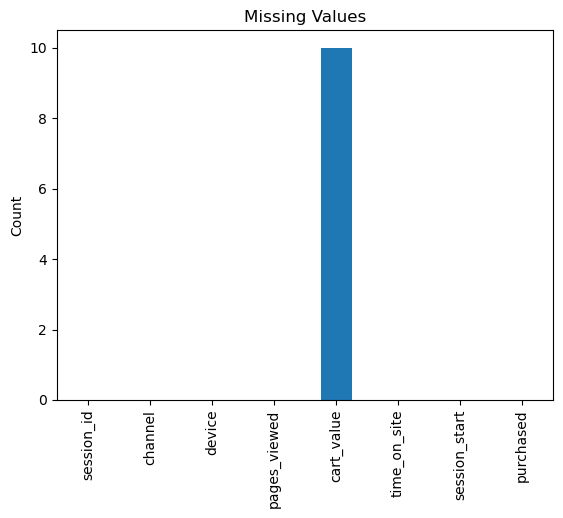

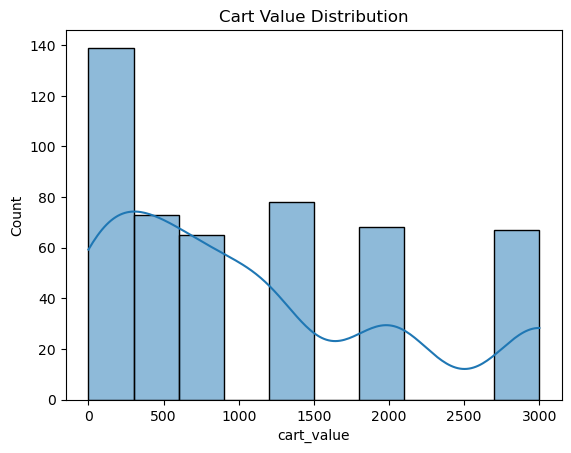

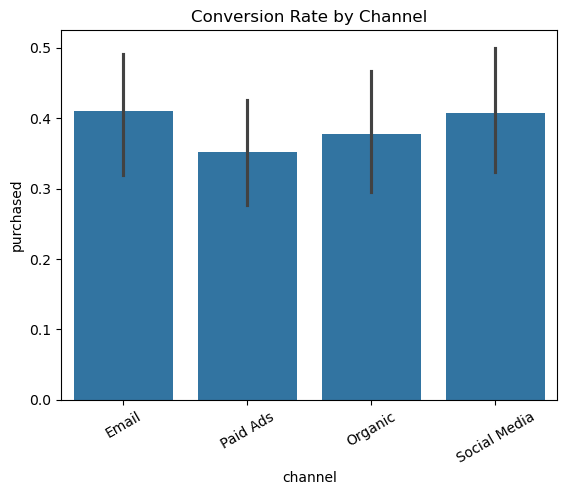

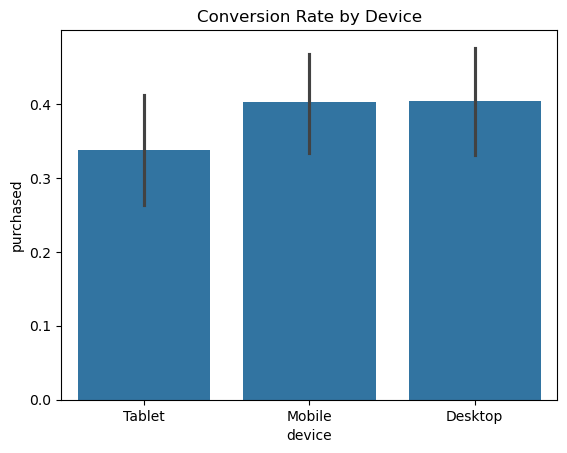

In [6]:
# Missing values visualization
df.isnull().sum().plot(kind="bar", title="Missing Values")
plt.ylabel("Count")
plt.show()

# Cart value distribution
sns.histplot(df["cart_value"].dropna(), kde=True)
plt.title("Cart Value Distribution")
plt.show()

# Conversion by Channel
sns.barplot(data=df, x="channel", y="purchased")
plt.title("Conversion Rate by Channel")
plt.xticks(rotation=30)
plt.show()

# Conversion by Device
sns.barplot(data=df, x="device", y="purchased")
plt.title("Conversion Rate by Device")
plt.show()


Funnel Stage Counts:
Sessions         500
Viewed Pages     500
Added to Cart    420
Purchased        192
dtype: int64


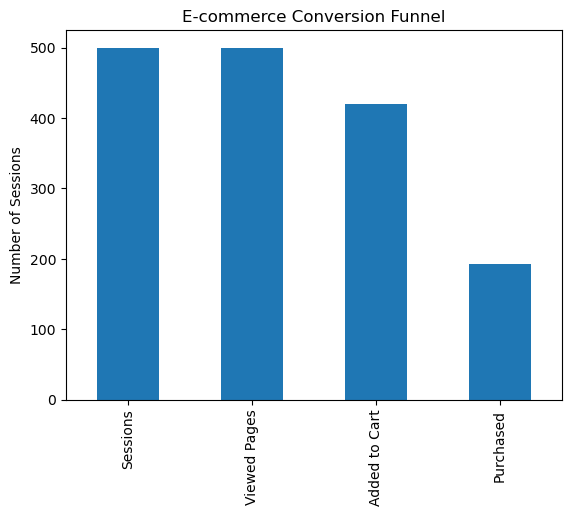

In [7]:
# 4. Funnel Analysis
funnel = pd.Series({
    "Sessions": len(df),
    "Viewed Pages": (df["pages_viewed"] > 0).sum(),
    "Added to Cart": (df["cart_value"] > 0).sum(),
    "Purchased": (df["purchased"] == 1).sum()
})

print("\nFunnel Stage Counts:")
print(funnel)

funnel.plot(kind="bar", title="E-commerce Conversion Funnel")
plt.ylabel("Number of Sessions")
plt.show()

In [8]:
# 5. Feature Engineering

df["pages_per_minute"] = (
    df["pages_viewed"] /
    (df["time_on_site"] / 60).replace(0, np.nan)
)

df["cart_value_bucket"] = pd.cut(
    df["cart_value"],
    bins=[-np.inf, 0, 500, 2000, np.inf],
    labels=["No Cart", "Low", "Medium", "High"]
)

df["session_hour"] = df["session_start"].dt.hour

In [9]:
# 6. Prepare Data for Prediction

features = [
    "channel", 
    "device", 
    "pages_viewed",
    "cart_value", 
    "time_on_site",
    "pages_per_minute", 
    "cart_value_bucket",
    "session_hour"
]

model_df = df.dropna(subset=["purchased", "session_hour"]).copy()

X = model_df[features]
y = model_df["purchased"].astype(int)

categorical = ["channel", "device", "cart_value_bucket"]
numerical = [
    "pages_viewed", "cart_value", "time_on_site",
    "pages_per_minute", "session_hour"
]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numerical),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical)
])

In [10]:
# 7. Model Building

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [11]:
# 8. Prediction
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [12]:
# 9. Evaluation

print("\nE-COMMERCE MODEL RESULTS")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("PR-AUC:", average_precision_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


E-COMMERCE MODEL RESULTS
Accuracy: 0.68
Precision: 0.6153846153846154
Recall: 0.42105263157894735
PR-AUC: 0.6146996375811963

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.84      0.76        62
           1       0.62      0.42      0.50        38

    accuracy                           0.68       100
   macro avg       0.66      0.63      0.63       100
weighted avg       0.67      0.68      0.66       100



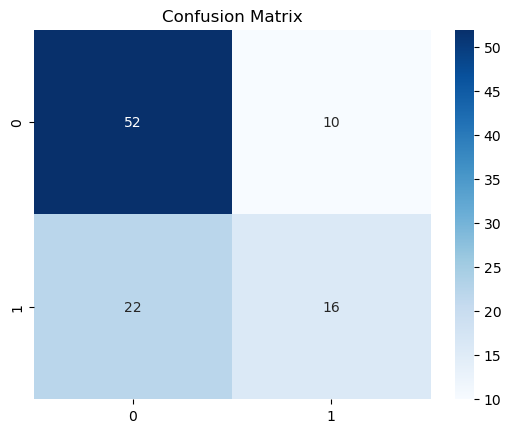

In [13]:
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True, fmt="d", cmap="Blues"
)
plt.title("Confusion Matrix")
plt.show()

### Recommendations

1. Improve channels with low conversion rates.
2. Simplify the checkout process.
3. Investigate sessions with high cart value but no purchase.

## Case study 2: Customer Churn
Question: identify customers at elevated risk of leaving so retention teams can prioritize outreach.
- EDA: churn rate by contract, tenure, support contacts and payment
method.
- Features: tenure_months, support_contacts_90d, average_monthly_usage, usage_change.
- Leakage warning: cancellation date or post-churn status cannot be used
as a predictor at an earlier decision point.
- Evaluation: recall/precision trade-off, PR-AUC for imbalance, and
intervention cost/benefit.

In [15]:
# Generate sample dataset
np.random.seed(42)

n = 500

df = pd.DataFrame({

    "customer_id": range(1001, 1001 + n),

    "contract": np.random.choice(
        ["Monthly", "Yearly", "Two-Year"],
        n,
        p=[0.55, 0.30, 0.15]
    ),

    "tenure_months": np.random.randint(1, 73, n),

    "support_contacts_90d": np.random.randint(0, 11, n),

    "average_monthly_usage": np.random.randint(10, 200, n),

    "usage_change": np.random.uniform(-50, 50, n).round(2),

    "payment_method": np.random.choice(
        ["Credit Card", "Debit Card", "UPI", "Bank Transfer"],
        n
    )
})

# Generate churn probability
score = (
    -2.0
    + (df["contract"] == "Monthly") * 0.9
    - (df["tenure_months"] * 0.025)
    + (df["support_contacts_90d"] * 0.15)
    - (df["usage_change"] * 0.015)
)

probability = 1 / (1 + np.exp(-score))

# Generate churn status
df["churn"] = np.where(
    np.random.random(n) < probability,
    1,
    0
)

# Add missing values for EDA
missing_rows = np.random.choice(n, 10, replace=False)

df.loc[missing_rows, "average_monthly_usage"] = np.nan

# Save CSV file
df.to_csv("customer_churn.csv", index=False)

print("Customer Churn Dataset Created Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Customer Churn Dataset Created Successfully!
Dataset Shape: (500, 8)


,customer_id,contract,tenure_months,support_contacts_90d,average_monthly_usage,usage_change,payment_method,churn
0,1001,Monthly,63,4,112.0,-7.73,Debit Card,0
1,1002,Two-Year,17,9,169.0,32.18,UPI,0
2,1003,Yearly,33,3,50.0,-49.88,UPI,0
3,1004,Yearly,29,8,123.0,-19.91,UPI,0
4,1005,Monthly,13,5,17.0,48.12,Bank Transfer,0


In [16]:
from sklearn.ensemble import RandomForestClassifier

# 1. Load Dataset
df = pd.read_csv("customer_churn.csv")

print("First Five Records:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

First Five Records:
   customer_id  contract  tenure_months  support_contacts_90d  \
0         1001   Monthly             63                     4   
1         1002  Two-Year             17                     9   
2         1003    Yearly             33                     3   
3         1004    Yearly             29                     8   
4         1005   Monthly             13                     5   

   average_monthly_usage  usage_change payment_method  churn  
0                  112.0         -7.73     Debit Card      0  
1                  169.0         32.18            UPI      0  
2                   50.0        -49.88            UPI      0  
3                  123.0        -19.91            UPI      0  
4                   17.0         48.12  Bank Transfer      0  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 -----

In [17]:
# 2. Data Cleaning
df = df.drop_duplicates(subset="customer_id")

df["churn"] = (
    df["churn"].astype(str).str.lower()
    .map({"yes": 1, "true": 1, "1": 1,
          "no": 0, "false": 0, "0": 0})
)


Churn Distribution:
churn
0    404
1     96
Name: count, dtype: int64

Churn by Contract:
contract
Monthly     0.202206
Two-Year    0.156627
Yearly      0.193103
Name: churn, dtype: float64

Churn by Payment Method:
payment_method
Bank Transfer    0.175000
Credit Card      0.237410
Debit Card       0.200000
UPI              0.150794
Name: churn, dtype: float64


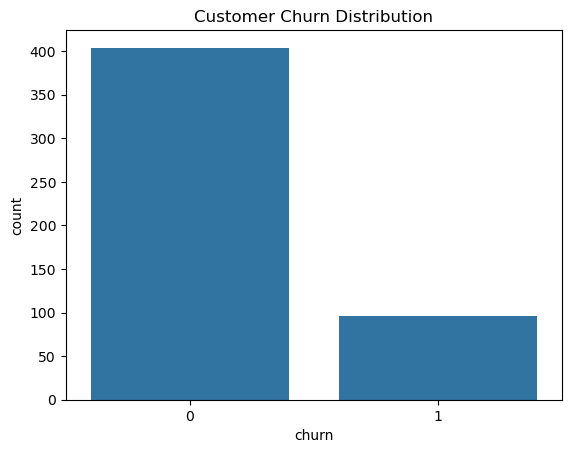

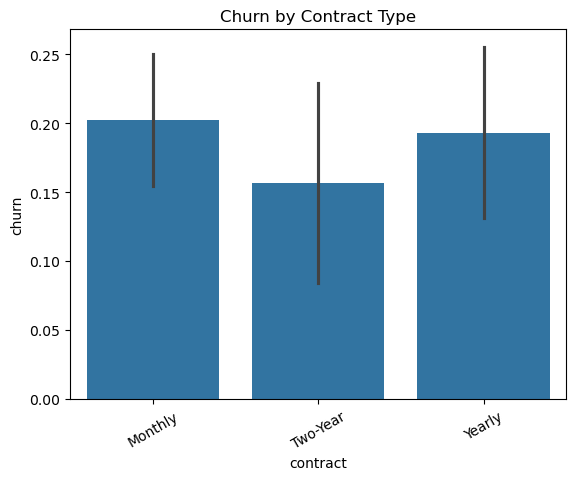

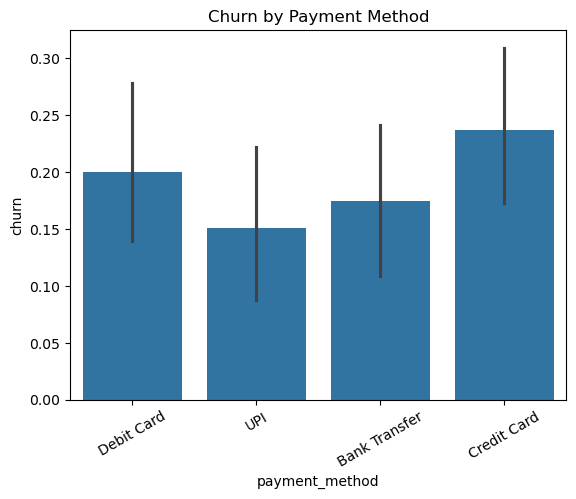

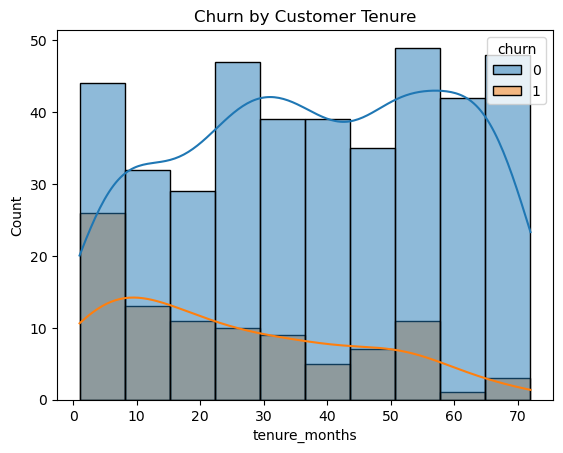

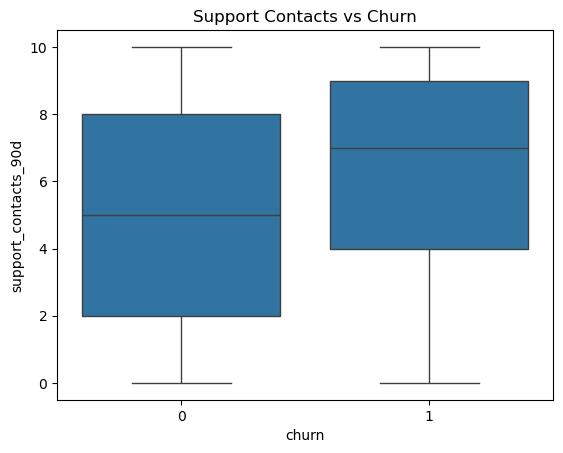

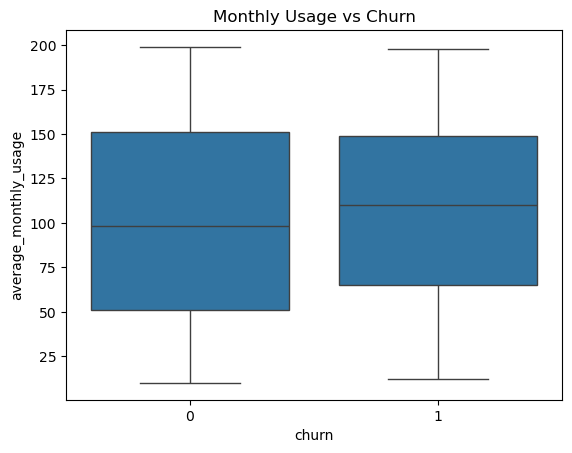

In [18]:
# 3. EDA

print("\nChurn Distribution:")
print(df["churn"].value_counts())

print("\nChurn by Contract:")
print(df.groupby("contract")["churn"].mean())

print("\nChurn by Payment Method:")
print(df.groupby("payment_method")["churn"].mean())

# Churn distribution
sns.countplot(data=df, x="churn")
plt.title("Customer Churn Distribution")
plt.show()

# Churn by Contract
sns.barplot(data=df, x="contract", y="churn")
plt.title("Churn by Contract Type")
plt.xticks(rotation=30)
plt.show()

# Churn by Payment Method
sns.barplot(data=df, x="payment_method", y="churn")
plt.title("Churn by Payment Method")
plt.xticks(rotation=30)
plt.show()

# Tenure distribution
sns.histplot(
    data=df, x="tenure_months",
    hue="churn", kde=True
)
plt.title("Churn by Customer Tenure")
plt.show()

# Support contacts
sns.boxplot(data=df, x="churn", y="support_contacts_90d")
plt.title("Support Contacts vs Churn")
plt.show()

# Usage analysis
sns.boxplot(data=df, x="churn", y="average_monthly_usage")
plt.title("Monthly Usage vs Churn")
plt.show()

In [19]:
# 4. Feature Selection

features = [
    "contract",
    "tenure_months",
    "support_contacts_90d",
    "average_monthly_usage",
    "usage_change",
    "payment_method"
]

# Exclude cancellation date and all post-churn information
model_df = df.dropna(subset=["churn"]).copy()

X = model_df[features]
y = model_df["churn"].astype(int)

categorical = ["contract", "payment_method"]

numerical = [
    "tenure_months",
    "support_contacts_90d",
    "average_monthly_usage",
    "usage_change"
]

In [20]:
# 5. Data Preprocessing

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numerical),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical)
])

In [21]:
# 6. Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)

In [22]:
# 7. Model Building

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)


,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [23]:
# 8. Prediction

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [24]:
# 9. Model Evaluation

print("\nCUSTOMER CHURN RESULTS")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("PR-AUC:", average_precision_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


CUSTOMER CHURN RESULTS
Accuracy: 0.79
Precision: 0.0
Recall: 0.0
PR-AUC: 0.2983698180880139

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.98      0.88        81
           1       0.00      0.00      0.00        19

    accuracy                           0.79       100
   macro avg       0.40      0.49      0.44       100
weighted avg       0.65      0.79      0.71       100



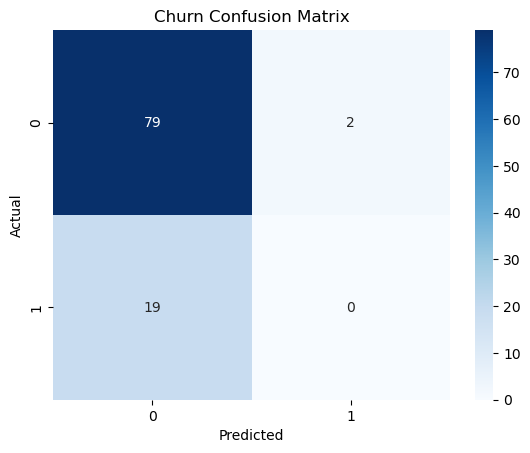

In [25]:
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True, fmt="d", cmap="Blues"
)
plt.title("Churn Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [26]:
# 10. Identify High-Risk Customers

results = model_df.loc[X_test.index, ["customer_id"]].copy()
results["Churn_Probability"] = y_prob
results["Risk"] = np.where(
    results["Churn_Probability"] >= 0.5,
    "High Risk", "Low Risk"
)

print("\nHIGH-RISK CUSTOMERS:")
print(
    results[results["Risk"] == "High Risk"]
    .sort_values("Churn_Probability", ascending=False)
)


HIGH-RISK CUSTOMERS:
     customer_id  Churn_Probability       Risk
216         1217               0.55  High Risk
212         1213               0.54  High Risk


### Recommendations

1. Prioritize high-risk customers for outreach.
2. Improve customer support services.
3. Offer suitable retention plans.
4. Monitor changes in customer usage.

## Case study 3: banking transaction anomalies
Question: flag unusual transactions for review; an anomaly is not
automatically fraud.
- EDA: transaction amount by channel/time, repeated merchants, class
imbalance and missing values.
- Features: amount relative to customer's history, transaction frequency
window, time since previous transaction.
- Use privacy-minimizing data, access controls and human review; assess
false positives and disparate impact.
- Use time-based validation to approximate deployment conditions.

In [30]:
np.random.seed(42)

n = 500

df = pd.DataFrame({
    "transaction_id": range(1, n + 1),

    "customer_id": np.random.randint(1001, 1051, n),

    "merchant": np.random.choice(
        ["Amazon", "Walmart", "Flipkart", "Grocery", "Restaurant"],
        n
    ),

    "channel": np.random.choice(
        ["UPI", "Card", "Online Banking", "ATM"],
        n
    ),

    "amount": np.random.randint(100, 5000, n),

    "transaction_time": pd.date_range(
        start="2026-01-01",
        periods=n,
        freq="30min"
    )
})

# Introduce unusual transactions
anomaly_indices = np.random.choice(n, 25, replace=False)

df.loc[anomaly_indices, "amount"] = np.random.randint(
    15000, 50000, 25
)

df["anomaly"] = 0
df.loc[anomaly_indices, "anomaly"] = 1

# Add missing values
missing_indices = np.random.choice(n, 10, replace=False)
df.loc[missing_indices, "amount"] = np.nan

df.to_csv("banking_transactions.csv", index=False)

print("Banking Dataset Created Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Banking Dataset Created Successfully!
Dataset Shape: (500, 7)


,transaction_id,customer_id,merchant,channel,amount,transaction_time,anomaly
0,1,1039,Restaurant,Online Banking,1885.0,2026-01-01 00:00:00,0
1,2,1029,Grocery,UPI,850.0,2026-01-01 00:30:00,0
2,3,1015,Amazon,ATM,1862.0,2026-01-01 01:00:00,0
3,4,1043,Restaurant,ATM,4020.0,2026-01-01 01:30:00,0
4,5,1008,Walmart,Card,4560.0,2026-01-01 02:00:00,0


In [31]:
from sklearn.ensemble import IsolationForest

# 1. Load Dataset

df = pd.read_csv("banking_transactions.csv")

print("First Five Records:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

First Five Records:
   transaction_id  customer_id    merchant         channel  amount  \
0               1         1039  Restaurant  Online Banking  1885.0   
1               2         1029     Grocery             UPI   850.0   
2               3         1015      Amazon             ATM  1862.0   
3               4         1043  Restaurant             ATM  4020.0   
4               5         1008     Walmart            Card  4560.0   

      transaction_time  anomaly  
0  2026-01-01 00:00:00        0  
1  2026-01-01 00:30:00        0  
2  2026-01-01 01:00:00        0  
3  2026-01-01 01:30:00        0  
4  2026-01-01 02:00:00        0  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    500 non-null    int64  
 1   customer_id       500 non-null    int64  
 2   merchant          500 non-null    ob

In [32]:
# 2. Data Cleaning

df = df.drop_duplicates(subset="transaction_id")

df["transaction_time"] = pd.to_datetime(
    df["transaction_time"]
)

df["amount"] = df["amount"].fillna(
    df["amount"].median()
)


Anomaly Distribution:
anomaly
0    475
1     25
Name: count, dtype: int64

Transactions by Channel:
channel
Online Banking    131
UPI               128
Card              128
ATM               113
Name: count, dtype: int64

Average Transaction Amount by Channel:
channel
ATM               4839.535398
Card              3456.656250
Online Banking    3255.354962
UPI               5338.445312
Name: amount, dtype: float64


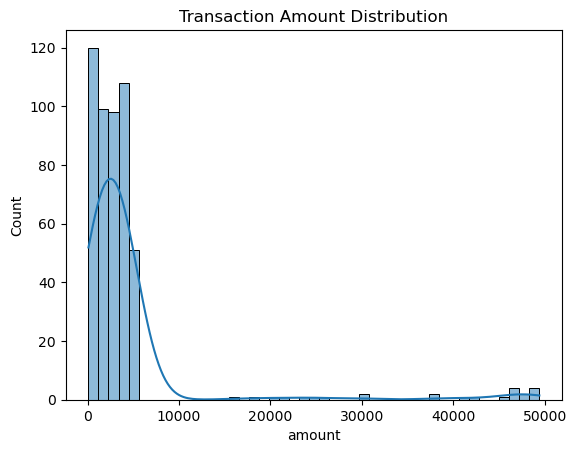

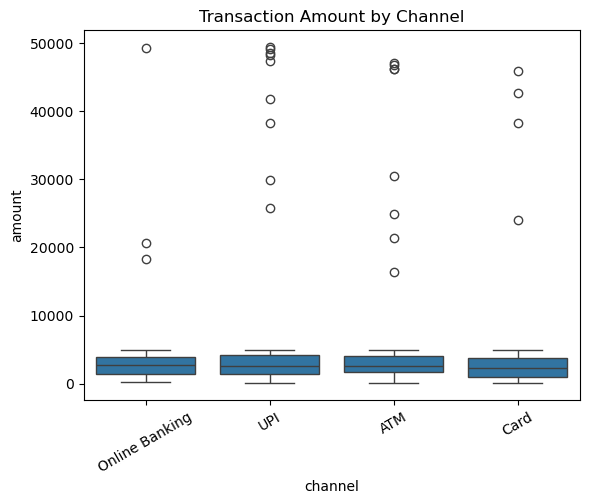

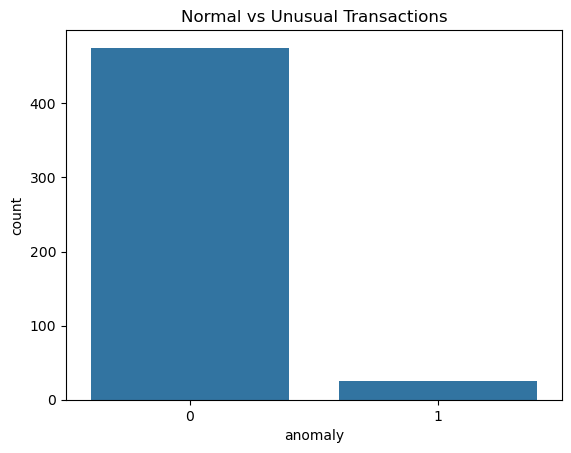

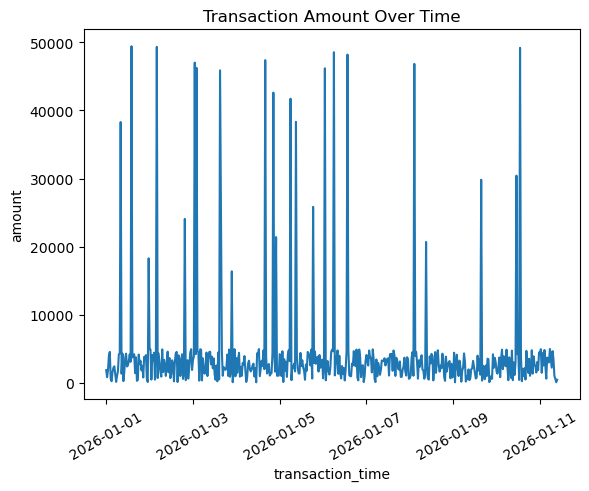

In [33]:
# 3. EDA

print("\nAnomaly Distribution:")
print(df["anomaly"].value_counts())

print("\nTransactions by Channel:")
print(df["channel"].value_counts())

print("\nAverage Transaction Amount by Channel:")
print(df.groupby("channel")["amount"].mean())

# Transaction amount distribution
sns.histplot(data=df, x="amount", kde=True)
plt.title("Transaction Amount Distribution")
plt.show()

# Transactions by channel
sns.boxplot(data=df, x="channel", y="amount")
plt.title("Transaction Amount by Channel")
plt.xticks(rotation=30)
plt.show()

# Anomaly distribution
sns.countplot(data=df, x="anomaly")
plt.title("Normal vs Unusual Transactions")
plt.show()

# Transactions by time
sns.lineplot(
    data=df,
    x="transaction_time",
    y="amount"
)
plt.title("Transaction Amount Over Time")
plt.xticks(rotation=30)
plt.show()

In [34]:
# 4. Feature Engineering

df = df.sort_values("transaction_time")

# Average transaction amount per customer
df["customer_avg_amount"] = (
    df.groupby("customer_id")["amount"]
    .transform(lambda x: x.expanding().mean().shift(1))
)

df["customer_avg_amount"] = (
    df["customer_avg_amount"].fillna(df["amount"].median())
)

# Transaction amount relative to customer history
df["amount_ratio"] = (
    df["amount"] / df["customer_avg_amount"]
)

# Transaction frequency
df["transaction_frequency"] = (
    df.groupby("customer_id")["transaction_id"]
    .transform(
        lambda x: x.rolling(5, min_periods=1).count()
    )
)

# Time since previous transaction
df["previous_transaction"] = (
    df.groupby("customer_id")["transaction_time"].shift(1)
)

df["time_since_previous"] = (
    df["transaction_time"] - df["previous_transaction"]
).dt.total_seconds() / 60

df["time_since_previous"] = (
    df["time_since_previous"].fillna(0)
)

# Transaction hour
df["transaction_hour"] = df["transaction_time"].dt.hour

In [35]:
# 5. Prepare Data

features = [
    "amount",
    "amount_ratio",
    "transaction_frequency",
    "time_since_previous",
    "transaction_hour"
]

X = df[features]
y = df["anomaly"]

In [36]:
# 6. Time-Based Train-Test Split

split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [37]:
# 7. Model Building

model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

model.fit(X_train)

,n_estimators,100
,max_samples,'auto'
,contamination,0.05
,max_features,1.0
,bootstrap,False
,n_jobs,None
,random_state,42
,verbose,0
,warm_start,False


In [38]:
# 8. Prediction

predictions = model.predict(X_test)

# Isolation Forest: -1 = Anomaly, 1 = Normal
y_pred = np.where(predictions == -1, 1, 0)

In [39]:
# 9. Model Evaluation

print("\nBANKING ANOMALY DETECTION RESULTS")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


BANKING ANOMALY DETECTION RESULTS
Accuracy: 0.98
Precision: 1.0
Recall: 0.5

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99        96
           1       1.00      0.50      0.67         4

    accuracy                           0.98       100
   macro avg       0.99      0.75      0.83       100
weighted avg       0.98      0.98      0.98       100



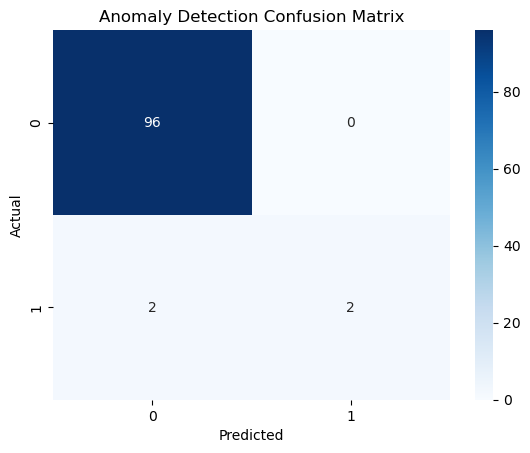

In [40]:
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Anomaly Detection Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [41]:
# 10. Identify Unusual Transactions

results = df.iloc[split:][
    ["transaction_id", "customer_id", "merchant",
     "channel", "amount"]
].copy()

results["Anomaly"] = y_pred

print("\nTRANSACTIONS FLAGGED FOR REVIEW:")

print(
    results[results["Anomaly"] == 1]
    .sort_values("amount", ascending=False)
)


TRANSACTIONS FLAGGED FOR REVIEW:
     transaction_id  customer_id  merchant channel   amount  Anomaly
458             459         1019  Flipkart     UPI  49171.0        1
454             455         1042   Grocery     ATM  30422.0        1


### Recommendations

1. Flag unusual transactions for human review.
2. Investigate unusually high transaction amounts.
3. Monitor repeated transactions and unusual activity.
4. Minimize customer data access and apply access controls.
5. Monitor false positives and potential bias.